# Activity 2: Binary Classification using Logistic Regression
## Regression and Classification Algorithms (RCA) – CIE 2



## 1. Problem statement and dataset

We will classify diagnostic records into two classes:
- **Malignant (0):** malignant tumour
- **Benign (1):** benign tumour

The dataset contains numerical measurements computed from digitized images of fine needle aspirates (FNA) of breast masses. The target is binary.

**Dataset source:** [Scikit-learn Breast Cancer Wisconsin dataset documentation](https://scikit-learn.org/stable/datasets/toy_dataset.html#breast-cancer-dataset)

**Important limitation:** This is an educational dataset and model. It must not be used to diagnose, screen, or make treatment decisions for real patients.


## 2. Import libraries

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, roc_curve,
    classification_report
)

RANDOM_STATE = 42

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

Python: 3.13.18
NumPy: 2.4.6
Pandas: 2.2.3
Scikit-learn: 1.6.1


## 3. Load and understand the dataset

In [2]:
cancer = load_breast_cancer(as_frame=True)
df = cancer.frame.copy()

# Scikit-learn's original target encoding: 0 = malignant, 1 = benign.
X = df.drop(columns="target")
y = df["target"]

print("First five records:")
display(df.head())

print("Dataset shape:", df.shape)
print("\nFeature count:", X.shape[1])
print("Target column: target")
print("\nTarget class names:", dict(enumerate(cancer.target_names)))
print("\nData types:")
display(df.dtypes.head())
print("\nDataset information:")
df.info()

First five records:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


Dataset shape: (569, 31)

Feature count: 30
Target column: target

Target class names: {0: np.str_('malignant'), 1: np.str_('benign')}

Data types:


,0
mean radius,float64
mean texture,float64
mean perimeter,float64
mean area,float64
mean smoothness,float64



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoo

## 4. Data inspection and cleaning

In [3]:
print("Missing values:")
display(df.isnull().sum().to_frame("Missing count"))

print("Duplicate rows:", df.duplicated().sum())

print("Summary statistics:")
display(df.describe())

print("Class counts (0 = malignant, 1 = benign):")
display(y.value_counts().sort_index())

# Remove exact duplicate rows if any.
df = df.drop_duplicates().copy()

# Separate features and target again after cleaning.
X = df.drop(columns="target")
y = df["target"]

# Impute numeric missing values with medians if any are present.
X = X.fillna(X.median())

print("Shape after cleaning:", df.shape)
print("Missing feature values after cleaning:", X.isnull().sum().sum())

Missing values:


,Missing count
mean radius,0
mean texture,0
mean perimeter,0
mean area,0
mean smoothness,0
mean compactness,0
mean concavity,0
mean concave points,0
mean symmetry,0
mean fractal dimension,0


Duplicate rows: 0
Summary statistics:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


Class counts (0 = malignant, 1 = benign):


,count
target,
0,212
1,357


Shape after cleaning: (569, 31)
Missing feature values after cleaning: 0


## 5. Visualize class distribution

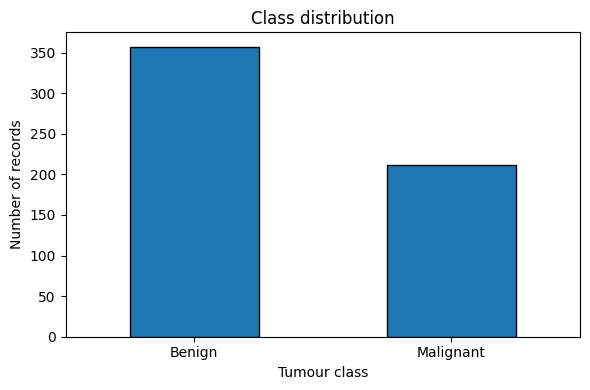

Class proportions:


,proportion
target,
Malignant,0.372583
Benign,0.627417


In [4]:
class_counts = y.map({0: "Malignant", 1: "Benign"}).value_counts()

plt.figure(figsize=(6, 4))
class_counts.plot(kind="bar", edgecolor="black")
plt.title("Class distribution")
plt.xlabel("Tumour class")
plt.ylabel("Number of records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("Class proportions:")
display(y.value_counts(normalize=True).sort_index().rename(index={0: "Malignant", 1: "Benign"}))

## 6. Prepare features and stratified train-test split

We use an 80:20 split with `stratify=y` so that the class proportions are approximately preserved in both sets. Scaling is performed inside a Pipeline: the scaler is fitted only on training data, preventing information from the test set leaking into preprocessing.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

split_counts = pd.DataFrame({
    "Train": y_train.value_counts().sort_index(),
    "Test": y_test.value_counts().sort_index()
}).rename(index={0: "Malignant", 1: "Benign"})
display(split_counts)

print("Training class proportions:")
display(y_train.value_counts(normalize=True).sort_index())
print("Testing class proportions:")
display(y_test.value_counts(normalize=True).sort_index())

Training feature shape: (455, 30)
Testing feature shape: (114, 30)


,Train,Test
target,,
Malignant,170,42
Benign,285,72


Training class proportions:


,proportion
target,
0,0.373626
1,0.626374


Testing class proportions:


,proportion
target,
0,0.368421
1,0.631579


## 7. Understand Logistic Regression and the sigmoid function

Logistic Regression estimates the probability of the positive class. The sigmoid function converts a score into a value between 0 and 1:

\\[
\\sigma(z) = \\frac{1}{1 + e^{-z}}
\\]

A default decision threshold of 0.5 assigns class 1 when the predicted probability is at least 0.5, and class 0 otherwise.

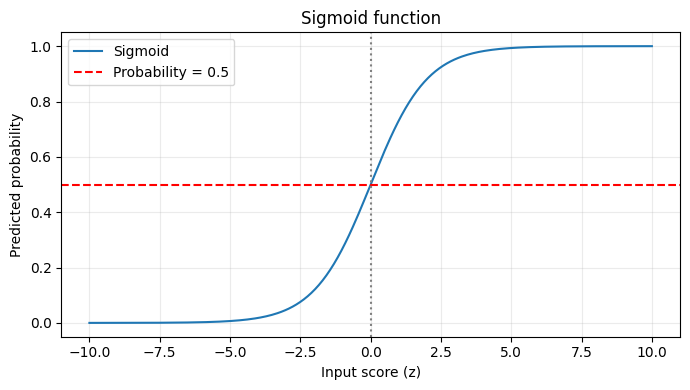

In [6]:
z = np.linspace(-10, 10, 300)
sigmoid = 1 / (1 + np.exp(-z))

plt.figure(figsize=(7, 4))
plt.plot(z, sigmoid, label="Sigmoid")
plt.axhline(0.5, color="red", linestyle="--", label="Probability = 0.5")
plt.axvline(0, color="gray", linestyle=":")
plt.xlabel("Input score (z)")
plt.ylabel("Predicted probability")
plt.title("Sigmoid function")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 8. Train Logistic Regression

In [7]:
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))
])

logistic_model.fit(X_train, y_train)

# Probability of class 1 (benign), and predicted labels at default threshold 0.5.
y_probability = logistic_model.predict_proba(X_test)[:, 1]
y_pred = (y_probability >= 0.5).astype(int)

print("Model trained successfully.")
print("Intercept:", logistic_model.named_steps["logistic"].intercept_[0])

coefficient_table = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": logistic_model.named_steps["logistic"].coef_[0]
}).sort_values("Coefficient", key=np.abs, ascending=False)

display(coefficient_table)

Model trained successfully.
Intercept: 0.30220757353702


,Feature,Coefficient
21,worst texture,-1.255088
10,radius error,-1.082965
27,worst concave points,-0.953686
23,worst area,-0.947756
20,worst radius,-0.947616
28,worst symmetry,-0.939181
13,area error,-0.929104
26,worst concavity,-0.823151
22,worst perimeter,-0.763220
24,worst smoothness,-0.746625


### Coefficient interpretation

The model predicts the probability of class 1 (benign). A positive coefficient increases the log-odds of the benign class as that feature increases, holding the other included features constant. A negative coefficient decreases those log-odds. Since the model uses standardized features, each coefficient corresponds to a one-standard-deviation feature increase. Coefficients are associations, not causal effects.


## 9. Predicted probabilities and class labels

In [8]:
prediction_sample = pd.DataFrame({
    "Actual label": y_test.to_numpy(),
    "Probability of benign (class 1)": y_probability,
    "Predicted label at threshold 0.5": y_pred
}, index=y_test.index)

prediction_sample["Actual class"] = prediction_sample["Actual label"].map(
    {0: "Malignant", 1: "Benign"}
)
prediction_sample["Predicted class"] = prediction_sample[
    "Predicted label at threshold 0.5"
].map({0: "Malignant", 1: "Benign"})

display(prediction_sample.head(10))

,Actual label,Probability of benign (class 1),Predicted label at threshold 0.5,Actual class,Predicted class
256,0,5.888242e-08,0,Malignant,Malignant
428,1,9.999887e-01,1,Benign,Benign
501,0,6.410825e-03,0,Malignant,Malignant
363,1,5.335085e-01,1,Benign,Benign
564,0,6.525001e-10,0,Malignant,Malignant
464,1,9.921604e-01,1,Benign,Benign
358,1,9.999828e-01,1,Benign,Benign
343,0,5.635275e-07,0,Malignant,Malignant
516,0,5.431637e-05,0,Malignant,Malignant
567,0,8.041849e-11,0,Malignant,Malignant


## 10. Confusion matrix and classification metrics

Confusion matrix (rows = actual, columns = predicted):
[[41  1]
 [ 1 71]]


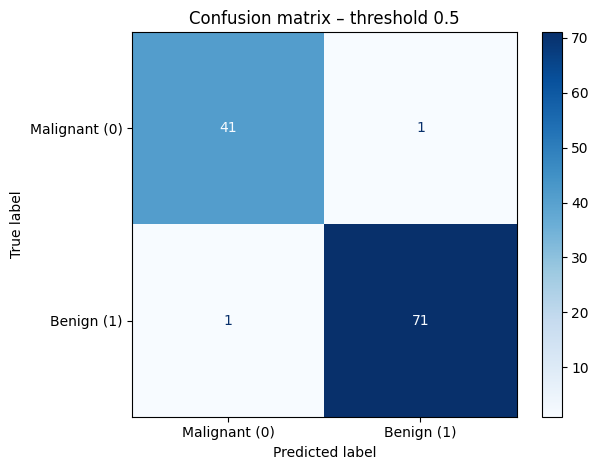

,Metric,Value
0,Accuracy,0.982456
1,Precision (class 1),0.986111
2,Recall / Sensitivity (class 1),0.986111
3,Specificity (class 0),0.976190
4,F1-score (class 1),0.986111
5,ROC-AUC,0.995370


TN = 41: actual malignant predicted malignant
FP = 1: actual malignant predicted benign
FN = 1: actual benign predicted malignant
TP = 71: actual benign predicted benign


In [9]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

print("Confusion matrix (rows = actual, columns = predicted):")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Malignant (0)", "Benign (1)"]
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion matrix – threshold 0.5")
plt.tight_layout()
plt.show()

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label=1, zero_division=0)
recall = recall_score(y_test, y_pred, pos_label=1, zero_division=0)
specificity = tn / (tn + fp) if (tn + fp) else 0
f1 = f1_score(y_test, y_pred, pos_label=1, zero_division=0)
roc_auc = roc_auc_score(y_test, y_probability)

metrics_table = pd.DataFrame({
    "Metric": ["Accuracy", "Precision (class 1)", "Recall / Sensitivity (class 1)",
               "Specificity (class 0)", "F1-score (class 1)", "ROC-AUC"],
    "Value": [accuracy, precision, recall, specificity, f1, roc_auc]
})
display(metrics_table)

print(f"TN = {tn}: actual malignant predicted malignant")
print(f"FP = {fp}: actual malignant predicted benign")
print(f"FN = {fn}: actual benign predicted malignant")
print(f"TP = {tp}: actual benign predicted benign")

### Metric formulas and meaning

- **Accuracy** = (TP + TN) / (TP + TN + FP + FN): proportion of all predictions that are correct.
- **Precision** = TP / (TP + FP): of records predicted positive, how many are truly positive.
- **Recall (sensitivity)** = TP / (TP + FN): of truly positive records, how many the model identifies.
- **Specificity** = TN / (TN + FP): of truly negative records, how many the model identifies.
- **F1-score** = 2 × (precision × recall) / (precision + recall): balances precision and recall.
- **ROC-AUC**: measures how well the model ranks positive records above negative records across thresholds.

Here, positive class is **benign (1)** because that is Scikit-learn's class encoding. Interpret false positives and false negatives using these class definitions.


## 11. Classification report

In [10]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["Malignant (0)", "Benign (1)"],
    zero_division=0
))

               precision    recall  f1-score   support

Malignant (0)       0.98      0.98      0.98        42
   Benign (1)       0.99      0.99      0.99        72

     accuracy                           0.98       114
    macro avg       0.98      0.98      0.98       114
 weighted avg       0.98      0.98      0.98       114



## 12. Compare with majority-class baseline

In [11]:
baseline_model = DummyClassifier(strategy="most_frequent")
baseline_model.fit(X_train, y_train)
baseline_pred = baseline_model.predict(X_test)

baseline_accuracy = accuracy_score(y_test, baseline_pred)
model_accuracy = accuracy_score(y_test, y_pred)

baseline_comparison = pd.DataFrame({
    "Model": ["Majority-class baseline", "Logistic Regression (threshold 0.5)"],
    "Accuracy": [baseline_accuracy, model_accuracy],
    "Precision (positive class)": [
        precision_score(y_test, baseline_pred, zero_division=0),
        precision_score(y_test, y_pred, zero_division=0)
    ],
    "Recall (positive class)": [
        recall_score(y_test, baseline_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0)
    ],
    "F1-score (positive class)": [
        f1_score(y_test, baseline_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0)
    ]
})
display(baseline_comparison)

,Model,Accuracy,Precision (positive class),Recall (positive class),F1-score (positive class)
0,Majority-class baseline,0.631579,0.631579,1.000000,0.774194
1,Logistic Regression (threshold 0.5),0.982456,0.986111,0.986111,0.986111


## 13. Study decision thresholds: 0.3, 0.5 and 0.7

A lower threshold predicts more records as the positive class (benign), which can increase recall for benign records but may reduce precision. A higher threshold predicts fewer positive records, which may increase precision but reduce recall. The preferred threshold depends on the real-world cost of each error.

In [12]:
threshold_rows = []

for threshold in [0.3, 0.5, 0.7]:
    threshold_pred = (y_probability >= threshold).astype(int)
    tn_t, fp_t, fn_t, tp_t = confusion_matrix(
        y_test, threshold_pred, labels=[0, 1]
    ).ravel()

    threshold_rows.append({
        "Threshold": threshold,
        "Predicted positive count": int((threshold_pred == 1).sum()),
        "Accuracy": accuracy_score(y_test, threshold_pred),
        "Precision": precision_score(y_test, threshold_pred, zero_division=0),
        "Recall": recall_score(y_test, threshold_pred, zero_division=0),
        "Specificity": tn_t / (tn_t + fp_t) if (tn_t + fp_t) else 0,
        "F1-score": f1_score(y_test, threshold_pred, zero_division=0)
    })

threshold_table = pd.DataFrame(threshold_rows)
display(threshold_table)

,Threshold,Predicted positive count,Accuracy,Precision,Recall,Specificity,F1-score
0,0.3,74,0.982456,0.972973,1.000000,0.952381,0.986301
1,0.5,72,0.982456,0.986111,0.986111,0.976190,0.986111
2,0.7,68,0.947368,0.985294,0.930556,0.976190,0.957143


## 14. ROC curve and ROC-AUC

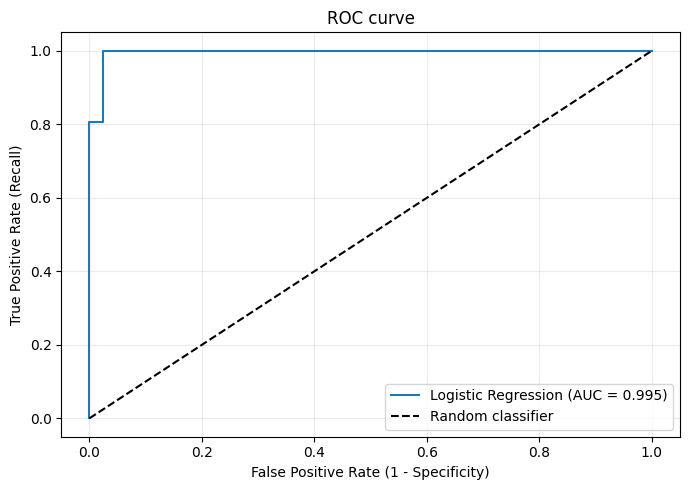

ROC-AUC: 0.9953703703703703


In [13]:
fpr, tpr, roc_thresholds = roc_curve(y_test, y_probability, pos_label=1)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC curve")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print("ROC-AUC:", roc_auc)

## 15. Visualize predicted probability against one feature

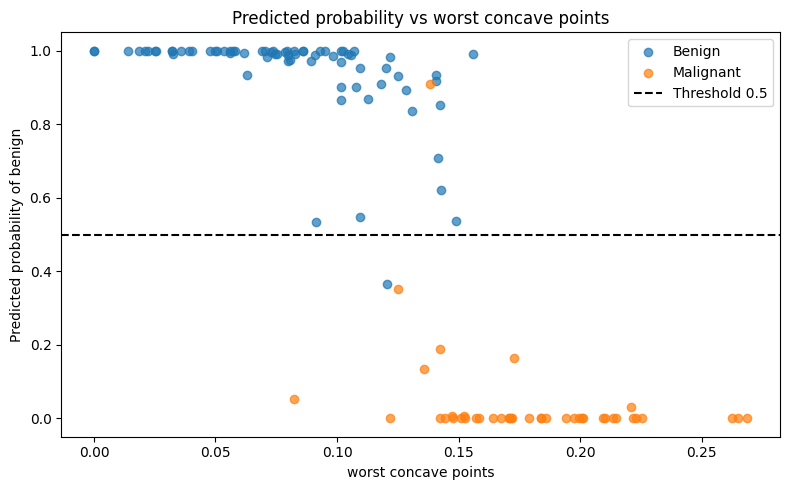

Feature plotted: worst concave points


In [14]:
# Display probability against the most strongly correlated feature in the training set.
strongest_feature = X_train.corrwith(y_train).abs().idxmax()
plot_data = pd.DataFrame({
    strongest_feature: X_test[strongest_feature],
    "Predicted probability of benign": y_probability,
    "Actual class": y_test.map({0: "Malignant", 1: "Benign"})
})

plt.figure(figsize=(8, 5))
for class_name, group in plot_data.groupby("Actual class"):
    plt.scatter(
        group[strongest_feature],
        group["Predicted probability of benign"],
        alpha=0.7,
        label=class_name
    )

plt.axhline(0.5, color="black", linestyle="--", label="Threshold 0.5")
plt.xlabel(strongest_feature)
plt.ylabel("Predicted probability of benign")
plt.title(f"Predicted probability vs {strongest_feature}")
plt.legend()
plt.tight_layout()
plt.show()

print("Feature plotted:", strongest_feature)

## 16. Classify a new example

In [15]:
# Use a real held-out test record as a new example so all values are valid
# and drawn from the dataset's observed feature ranges.
new_example = X_test.iloc[[0]].copy()

new_probability = logistic_model.predict_proba(new_example)[0, 1]
new_class = int(new_probability >= 0.5)
new_label = {0: "Malignant", 1: "Benign"}[new_class]

print("New example input:")
display(new_example)
print(f"Predicted probability of benign: {new_probability:.4f}")
print(f"Predicted class at threshold 0.5: {new_class} ({new_label})")

New example input:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
256,19.55,28.77,133.6,1207.0,0.0926,0.2063,0.1784,0.1144,0.1893,0.06232,...,25.05,36.27,178.6,1926.0,0.1281,0.5329,0.4251,0.1941,0.2818,0.1005


Predicted probability of benign: 0.0000
Predicted class at threshold 0.5: 0 (Malignant)


## 17. Conclusion and decision log

In [16]:
print("FINAL SUMMARY")
print("-------------")
print(f"Majority-class baseline accuracy: {baseline_accuracy:.4f}")
print(f"Logistic Regression accuracy: {accuracy:.4f}")
print(f"Precision (positive = benign): {precision:.4f}")
print(f"Recall (positive = benign): {recall:.4f}")
print(f"Specificity (negative = malignant): {specificity:.4f}")
print(f"F1-score: {f1:.4f}")
print(f"ROC-AUC: {roc_auc:.4f}")

print("\nThreshold comparison:")
display(threshold_table)

print("\nUse the threshold table and the consequences of FP/FN to justify a threshold.")
print("This educational model is not suitable for medical diagnosis.")

FINAL SUMMARY
-------------
Majority-class baseline accuracy: 0.6316
Logistic Regression accuracy: 0.9825
Precision (positive = benign): 0.9861
Recall (positive = benign): 0.9861
Specificity (negative = malignant): 0.9762
F1-score: 0.9861
ROC-AUC: 0.9954

Threshold comparison:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Threshold,Predicted positive count,Accuracy,Precision,Recall,Specificity,F1-score
0,0.3,74,0.982456,0.972973,1.000000,0.952381,0.986301
1,0.5,72,0.982456,0.986111,0.986111,0.976190,0.986111
2,0.7,68,0.947368,0.985294,0.930556,0.976190,0.957143



Use the threshold table and the consequences of FP/FN to justify a threshold.
This educational model is not suitable for medical diagnosis.
